# Plant Leaf Disease Analysis Using Segmentation and Machine Learning

COM0418 Image Processing · Emre Cantürk and Merve Gündoğdu

We compare binary **Healthy/Diseased** classification using full-image features (A) and predicted leaf-mask features (B). Both methods use 48 HSV histogram bins, 10 uniform LBP bins, StandardScaler, and an RBF SVM. Plant species and original disease labels are metadata, not prediction targets.

The primary outcome is held-out macro F1 for B minus A. A negative difference is a valid result. This notebook runs locally in the project kernel or in Colab using the companion archive. Reference outlines require both team members' review before final segmentation evaluation. Development CV outputs shown before that review are provisional.


## 1 Environment and project files

**Google Colab (submission route):** open the notebook in Colab and choose **Runtime > Run all**. No upload or manual step is needed. The next cell:

1. clones the code, manifests and annotations from the project's GitHub repository at `REPO_REF`;
2. installs the pinned processing packages from `requirements-colab.txt` (Colab's own Jupyter packages are left untouched);
3. downloads the saved models and recorded results (`shared_artifacts.zip`) from the shared Google Drive project folder, using the file ID in `SHARED_ARTIFACTS_ID`. The file is shared as "anyone with the link can view", so no sign-in is required;
4. restores the 900 original images from their pinned PlantVillage source URLs with checksum verification (section 2).

If Colab had already loaded a different NumPy version, the cell restarts the runtime once and asks you to choose **Run all** again; the second run skips the finished steps. Without `SHARED_ARTIFACTS_ID`, the notebook still runs end to end and refits the development models itself.

**Local:** launch `Start Jupyter Lab.command`, open this notebook, and select **Leaf Disease (.venv)**. The settings in the next cell are ignored locally.


In [1]:
from pathlib import Path
import importlib.metadata, os, sys, json, zipfile, stat, subprocess, shutil

# Hosted-run settings (ignored outside Colab).
REPO_URL = 'https://github.com/thrustec/plant-leaf-disease-analysis.git'
REPO_REF = 'a8bd034c8e8ec04e8bfb757bca39f19eb656b070'
SHARED_ARTIFACTS_ID = '1QHfBnQg6yLIElWTAyRJzjDad9ofgyBgi'
COLAB_CHECKOUT = Path('/content/plant-leaf-disease-analysis')

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def safe_extract(archive_path, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination) or stat.S_ISLNK(member.external_attr >> 16):
                raise ValueError('Archive contains an unsafe path or symbolic link.')
        archive.extractall(destination)


if IN_COLAB and not Path('leaf_pipeline.py').exists():
    if not (COLAB_CHECKOUT / 'leaf_pipeline.py').exists():
        subprocess.check_call(['git', 'clone', '--quiet', REPO_URL, str(COLAB_CHECKOUT)])
        subprocess.check_call(['git', '-C', str(COLAB_CHECKOUT), 'checkout', '--quiet', REPO_REF])
    os.chdir(COLAB_CHECKOUT)

if IN_COLAB:
    loaded_numpy = sys.modules.get('numpy')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'])
    # experiment.environment() records these; install only if Colab lacks them, never replace Colab's kernel.
    for name, pinned in (('jupyterlab', '4.6.4'), ('nbclient', '0.11.0'), ('nbformat', '5.11.1'), ('ipykernel', '7.4.0')):
        try:
            importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'{name}=={pinned}'])
    if loaded_numpy is not None and loaded_numpy.__version__ != importlib.metadata.version('numpy'):
        print('Pinned packages installed. The runtime restarts once now: choose Runtime > Run all again.')
        os.kill(os.getpid(), 9)

artifacts_marker = Path('models/.shared_artifacts')
if IN_COLAB and SHARED_ARTIFACTS_ID and not artifacts_marker.exists():
    archive = Path('shared_artifacts.zip')
    if Path(SHARED_ARTIFACTS_ID).is_file():
        shutil.copy(SHARED_ARTIFACTS_ID, archive)
    else:
        import gdown
        if not gdown.download(id=SHARED_ARTIFACTS_ID, output=str(archive), quiet=True):
            raise RuntimeError('Could not download shared_artifacts.zip; check that the Drive file is shared by link.')
    safe_extract(archive, Path.cwd())
    artifacts_marker.parent.mkdir(exist_ok=True)
    artifacts_marker.write_text(SHARED_ARTIFACTS_ID)
    print('Restored saved models and results:', sorted(str(p) for p in Path('models').glob('*') if p.name != '.shared_artifacts'))

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'leaf_pipeline.py').exists():
    raise FileNotFoundError('Open the notebook from the project folder, with the shared Python files.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache/matplotlib')
print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('Colab runtime:', IN_COLAB)
if IN_COLAB:
    print('Code revision:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())


Python: 3.11.0
Interpreter: /Users/emrecanturk/Desktop/Image Processing/.venv/bin/python
Colab runtime: False


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from collections import Counter
from leaf_pipeline import LABELS, load_rgb, overlay_mask, predict_image, read_manifest
from prepare_data import prepare, validate_dataset
from mask_review import prepare_reviews, export_reviewed, review_status, reviewed_references
from experiment import run_development, freeze, evaluate_final, environment
cv2.setNumThreads(1)
# experiment.py selects the non-interactive Agg backend for scripts; restore inline figures here.
%matplotlib inline
display(environment())


{'python': '3.11.0',
 'os': 'macOS-26.5.2-arm64-arm-64bit',
 'machine': 'arm64',
 'logical_cpus': 8,
 'opencv_threads': 8,
 'packages': {'numpy': '2.4.6',
  'opencv-python-headless': '4.14.0.94',
  'scikit-image': '0.26.0',
  'scikit-learn': '1.9.1',
  'matplotlib': '3.11.2',
  'joblib': '1.6.0',
  'jupyterlab': '4.6.4',
  'ipykernel': '7.4.0',
  'nbclient': '0.11.0',
  'nbformat': '5.11.1',
  'certifi': '2026.10.23'},
 'cpu': 'Apple M2',
 'memory_bytes': '17179869184'}

## 2 Data and fixed partitions

We target 150 Healthy and 150 Diseased images for each of Apple, Bell pepper, and Tomato. Only verified disease labels are included. Spider-mite damage is excluded. Grape was replaced because the selected source revision has no healthy-leaf grouping metadata; Apple black rot and Tomato mosaic were excluded because their grouping labels could not be resolved reliably for this subset.

We select one image per supplied leaf group. Exact/near-duplicate checks add conservative grouping constraints. The approximately 80/20 development/test partition and three development folds are fixed in the manifest. Group separation takes priority over exact split counts. Original files are read-only.


In [3]:
rows = prepare(PROJECT_ROOT)
validate_dataset(PROJECT_ROOT)
counts = Counter((row['plant'], row['health'], row['partition']) for row in rows)
lines = ['| Plant | Health | Development | Test |', '|---|---|---:|---:|']
for plant in sorted({row['plant'] for row in rows}):
    for health in LABELS:
        lines.append(f"| {plant} | {health} | {counts[plant, health, 'development']} | {counts[plant, health, 'test']} |")
display(Markdown('\n'.join(lines)))
print('Fixed source revision:', rows[0]['source_revision'])
print('Group and hash separation checks passed.')


Existing dataset verified; fixed partitions preserved.


| Plant | Health | Development | Test |
|---|---|---:|---:|
| Apple | Healthy | 120 | 30 |
| Apple | Diseased | 120 | 30 |
| Pepper,_bell | Healthy | 120 | 30 |
| Pepper,_bell | Diseased | 120 | 30 |
| Tomato | Healthy | 120 | 30 |
| Tomato | Diseased | 120 | 30 |

Fixed source revision: 7f7ecc7e1eaca78107e3affe7cb5abd9427e139a
Group and hash separation checks passed.


## 3 Independent reference outlines

There are 12 development and 18 test annotation images, balanced by plant and health state. Initial draft polygons use **GrabCut**, independently of Method B's Lab-distance segmentation. Nine development drafts were corrected after the team identified cast shadows, using traced priors, background seeds, and visible-tissue restorations. These revisions remain subject to both reviewers. Drafts are unreviewed suggestions and must be corrected against the original leaf image, including symptomatic yellow/brown tissue. Both team members review each polygon in Labelme and set their own image flag before saving.

Run `Review Development Masks.command` and `Review Test Masks.command` locally. In Colab, use references already reviewed locally; a desktop Qt GUI is not installed in the hosted runtime. The full review gallery is `results/mask_review/index.html`. Test outlines must not guide segmentation choices.


Reviewed references: {'development': 1}
Required: 12 development and 18 test, each reviewed by both members.
Review gallery: results/mask_review/index.html


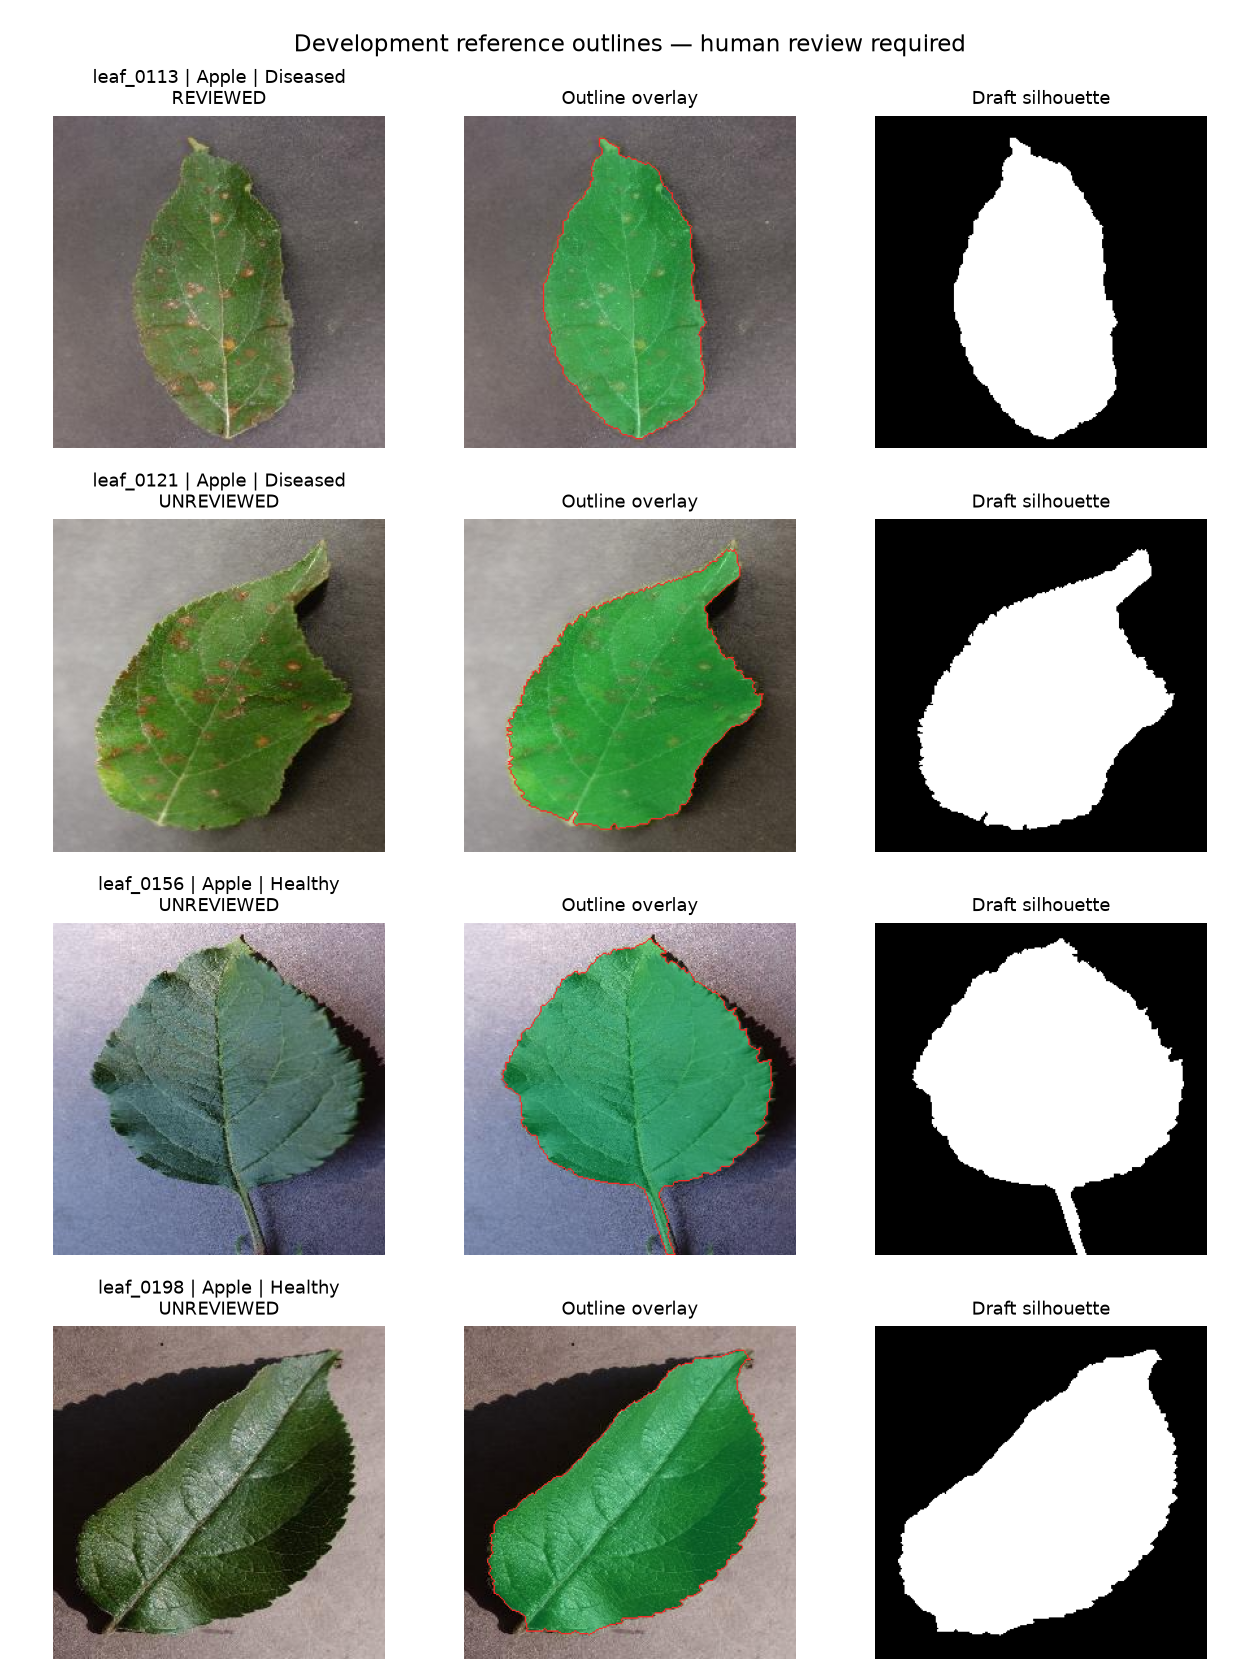

In [4]:
review_page = prepare_reviews(PROJECT_ROOT)
export_reviewed(PROJECT_ROOT)
status = review_status(PROJECT_ROOT)
reviewed = reviewed_references(PROJECT_ROOT)
print('Reviewed references:', dict(Counter(row['partition'] for row in reviewed)))
print('Required: 12 development and 18 test, each reviewed by both members.')
print('Review gallery:', review_page.relative_to(PROJECT_ROOT))
display(Image(filename=str(PROJECT_ROOT / 'results/mask_review/development_01.png'), width=850))


## 4 Image processing and the paired experiment

Method B estimates the background from image borders in floating-point Lab space, thresholds color distance, applies opening/closing, fills the largest external contour, and checks mask usability. We select a distance in {12, 18, 24} and closing size in {3, 5} using Dice on the **12 reviewed development outlines only**. Before review, the code uses a declared default and labels its results provisional.

HSV histograms use 16 bins independently for H, S, and V. Uniform LBP uses 8 neighbors, radius 1, and 10 bins. Only complete LBP neighborhoods inside the feature region contribute. Every histogram is normalized separately. Both methods therefore use 58 features.

Both SVMs use the same development images, three fixed group-safe folds, balanced class weights, gamma='scale', and C in {0.1, 1, 10}. StandardScaler is fitted inside each training fold. Any development samples with unusable masks are excluded from **both** methods' training and recorded. Test-mask failures are always retained in the final evaluation.


Method A: development CV macro F1 0.9444


Method B: development CV macro F1 0.8971


Segmentation status: provisional_unreviewed_masks
Shared training images: 720


{'A': {'cv_macro_f1': 0.9444438657306936,
  'C': 10.0,
  'search_and_refit_seconds': 0.10719908296596259,
  'final_refit_seconds': 0.007478952407836914},
 'B': {'cv_macro_f1': 0.8971290264163482,
  'C': 10.0,
  'search_and_refit_seconds': 0.1063731670146808,
  'final_refit_seconds': 0.007745027542114258}}

Development CV B minus A: -0.047314839314345436
These are development CV results, not final test results.


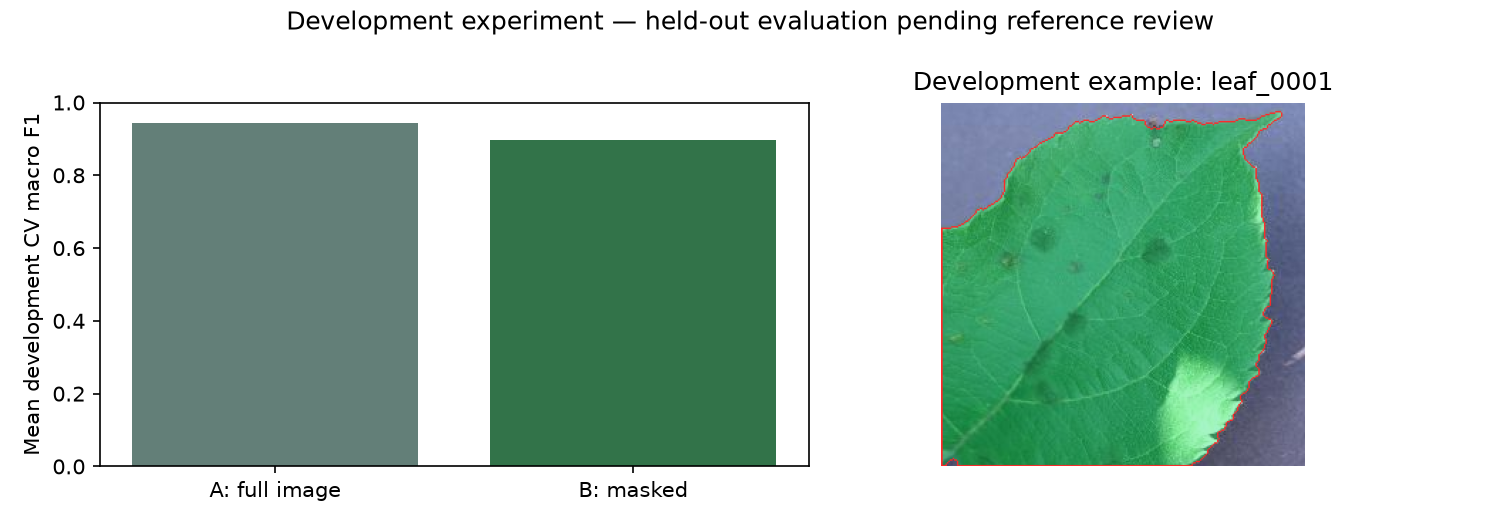

In [5]:
if (PROJECT_ROOT / 'models/frozen_protocol.json').exists():
    development = json.loads((PROJECT_ROOT / 'results/development/summary.json').read_text())
    print('Frozen models preserved; showing recorded development results.')
else:
    development = run_development(PROJECT_ROOT)
print('Segmentation status:', development['segmentation_status'])
print('Shared training images:', development['shared_training_images'])
display(development['methods'])
print('Development CV B minus A:', development['cv_macro_f1_B_minus_A'])
print('These are development CV results, not final test results.')
display(Image(filename=str(PROJECT_ROOT / 'results/development/development_overview.png'), width=900))


## 5 Single image demonstration

The default example comes from development data. Change `CUSTOM_IMAGE` to a local image path for your own input. Method B returns an explicit error when its mask is unusable. Model/scaler persistence uses the same shared pipeline as training. The demonstration does not establish accuracy on field photographs.


In [6]:
CUSTOM_IMAGE = None
example = next(row for row in rows if row['partition'] == 'development')
image_path = Path(CUSTOM_IMAGE) if CUSTOM_IMAGE else PROJECT_ROOT / example['path']
try:
    label, rgb, mask = predict_image(image_path, PROJECT_ROOT / 'models/development_B.joblib')
    figure, axes = plt.subplots(1, 3, figsize=(10, 4))
    for axis, image, title in zip(axes, [rgb, mask, overlay_mask(rgb, mask)], ['Original', 'Predicted leaf mask', label]):
        axis.imshow(image, cmap='gray' if image.ndim == 2 else None)
        axis.set_title(title)
        axis.axis('off')
    figure.tight_layout()
    display(figure)
    plt.close(figure)
except ValueError as error:
    print('Prediction unavailable:', error)


<Figure size 1000x400 with 3 Axes>

## 5b Interactive exploration

This section is meant to be edited. Change `SEGMENTATION_PARAMETERS`, pick another image, or upload your own, then rerun the cells below. The figures show every intermediate step of Method B's segmentation, the 58 features measured by A and B, and both saved models' predictions.

All outputs of this section go to `results/experiments/`. The saved models, the recorded development results, the frozen protocol and the locked final benchmark are never changed here.

- `distance`: Lab color distance above which a pixel counts as leaf. Smaller values keep more pixels, including shadows.
- `border`: width in pixels (1–128) of the image frame used to estimate the background color.
- `opening` / `closing`: elliptical kernel sizes that remove specks and fill small gaps.
- `EXAMPLE_IMAGE_ID`: a **development** `image_id` from `data/manifests/images.csv`, or `None` for the first development image. Locked test images are rejected here so they cannot guide parameter choices.
- `UPLOAD_NEW_IMAGE = True`: in Colab, opens a file picker so you can test your own leaf photo.


In [ ]:
from explore import (compare_methods, development_image_path, reproduce_final,
                     run_parameter_experiment, show_features, show_segmentation_steps, upload_images)
from leaf_pipeline import DEFAULT_SEGMENTATION

SEGMENTATION_PARAMETERS = dict(DEFAULT_SEGMENTATION)   # e.g. dict(DEFAULT_SEGMENTATION, distance=12.0)
EXAMPLE_IMAGE_ID = None                                # e.g. 'leaf_0121' (a shadow example)
UPLOAD_NEW_IMAGE = False                               # Colab only: choose your own image file

if UPLOAD_NEW_IMAGE:
    explore_image = upload_images(PROJECT_ROOT)[0]
elif EXAMPLE_IMAGE_ID:
    explore_image = development_image_path(rows, EXAMPLE_IMAGE_ID, PROJECT_ROOT)
else:
    explore_image = PROJECT_ROOT / next(r for r in rows if r['partition'] == 'development')['path']
print('Image:', explore_image.relative_to(PROJECT_ROOT) if explore_image.is_relative_to(PROJECT_ROOT) else explore_image)
print('Segmentation parameters:', SEGMENTATION_PARAMETERS)

figure, steps = show_segmentation_steps(explore_image, SEGMENTATION_PARAMETERS)
display(figure); plt.close(figure)
print('Estimated background Lab color:', np.round(steps['background_lab'], 2))


In [ ]:
figure, features = show_features(explore_image, SEGMENTATION_PARAMETERS)
display(figure); plt.close(figure)

figure, predictions = compare_methods(explore_image, PROJECT_ROOT)
display(figure); plt.close(figure)
display(predictions)
print('The saved models were trained with the recorded segmentation settings; the parameters above only change the figures and the experiment below.')


### Parameter experiment

The next cell reruns the paired development comparison with `SEGMENTATION_PARAMETERS`: same 720 development images, same three group-safe folds, same scaler, RBF SVM and C search as the recorded experiment. Only development data are used, so test images cannot influence parameter choices. When reviewed development outlines exist, the mean Dice against them is reported too. The same safeguards as the recorded pipeline apply: if fewer than 80% of development masks are usable, or a fold loses a health class, the cell stops without a score. If some masks are unusable, both methods are scored on the remaining images, and the table marks the result as not directly comparable with the recorded 720-image run.

With the default parameters the result reproduces the recorded development summary. A new parameter set takes roughly half a minute because features are recomputed; repeated sets are cached.


In [ ]:
EXPERIMENT_NAME = None   # None = timestamped folder; or e.g. 'distance_12'
experiment = run_parameter_experiment(SEGMENTATION_PARAMETERS, EXPERIMENT_NAME, PROJECT_ROOT)
recorded = experiment.get('recorded_development', {})
lines = ['| | This run | Recorded development |', '|---|---:|---:|']
for method in ('A', 'B'):
    now = experiment['methods'][method]['cv_macro_f1']
    then = recorded.get('methods', {}).get(method, {}).get('cv_macro_f1', float('nan'))
    lines.append(f'| Method {method} CV macro F1 | {now:.4f} | {then:.4f} |')
lines.append(f"| B minus A | {experiment['cv_macro_f1_B_minus_A']:+.4f} | {recorded.get('cv_macro_f1_B_minus_A', float('nan')):+.4f} |")
lines.append(f"| Development images scored (both methods) | {experiment['shared_training_images']} | {recorded.get('shared_training_images', '')} |")
lines.append(f"| Unusable development masks | {experiment['unusable_masks']} | |")
if 'mean_development_dice' in experiment:
    lines.append(f"| Mean Dice on {experiment['reviewed_development_references']} reviewed development outlines | {experiment['mean_development_dice']:.4f} | |")
display(Markdown('\n'.join(lines)))
if not experiment.get('comparable_to_recorded', True):
    print('Note: this run scored a different set of images than the recorded experiment; do not compare the F1 values directly.')
print('Segmentation used:', experiment['segmentation'])


## 6 Locked final evaluation

Leave `RUN_FINAL_EVALUATION=False` during development. After both people review all 30 references, export the reviews and rerun development so the 12 development references determine segmentation settings. Only then freeze the protocol and evaluate.

Final results include macro F1, accuracy, class precision/recall/F1/support, covered 2×2 confusion matrices with separate failure counts, per-plant errors, reference-mask IoU/Dice, and median preprocessing-to-prediction time on the same CPU. Diseased is the positive class. A failed prediction remains in the accuracy denominator and contributes a false negative to its true class for F1. Empty masks score zero for IoU/Dice. No test results are used to retune the methods.

A saved final result is shown without repeating the held-out evaluation. Stored models and protocol hashes are protected against accidental replacement.


In [7]:
RUN_FINAL_EVALUATION = False
final_path = PROJECT_ROOT / 'results/final/metrics.json'
if RUN_FINAL_EVALUATION:
    export_reviewed(PROJECT_ROOT)
    if not (PROJECT_ROOT / 'models/frozen_protocol.json').exists():
        freeze(PROJECT_ROOT)
    final_results = evaluate_final(PROJECT_ROOT)
    display(final_results)
elif final_path.exists():
    display(json.loads(final_path.read_text()))
else:
    print('Final test evaluation pending: human reference review and parameter freeze are required.')
    print('No final test macro F1 or segmentation score has been reported.')


Final test evaluation pending: human reference review and parameter freeze are required.
No final test macro F1 or segmentation score has been reported.


### Reproducing the locked evaluation

The stored benchmark above is shown without being overwritten. The next cell recomputes the complete test evaluation from the frozen models in a temporary copy of the project and compares every headline metric with the stored values. Results are written to `results/experiments/final_reproduction/`. It runs only after the protocol has been frozen and evaluated, and takes a few minutes because each test image is timed three times per method.


In [ ]:
REPRODUCE_FINAL_EVALUATION = True
if REPRODUCE_FINAL_EVALUATION and final_path.exists():
    comparison = reproduce_final(PROJECT_ROOT)
    lines = ['| Method | Metric | Stored | Recomputed | Match |', '|---|---|---:|---:|---|']
    lines += [f"| {r['method']} | {r['metric']} | {r['stored']:.4f} | {r['recomputed']:.4f} | {'yes' if r['match'] else 'NO'} |" for r in comparison]
    display(Markdown('\n'.join(lines)))
else:
    print('No stored final benchmark yet; reproduction becomes available after freeze and evaluation.')


## 7 Interpretation and next steps

Compare B minus A test macro F1, mask quality, failure coverage, runtime, and errors by plant. A high score on controlled PlantVillage images does not establish field generalization. The 18 reference test outlines support a small diagnostic segmentation study. Discuss mislabeled/ambiguous symptoms, background bias, symptomatic tissue loss, and remaining limitations of source grouping and near-duplicate heuristics.

The final report and presentation will use saved final experiment tables and figures. They remain pending until reviewed masks and locked evaluation exist.

## References

- [PlantVillage primary repository](https://github.com/spMohanty/PlantVillage-Dataset)
- [Mohanty et al. 2016](https://doi.org/10.3389/fpls.2016.01419)
- [OpenCV morphology](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)
- [OpenCV GrabCut](https://docs.opencv.org/4.x/d8/d83/tutorial_py_grabcut.html)
- [scikit-image LBP](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_local_binary_pattern.html)
- [scikit-learn SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [Labelme](https://github.com/wkentaro/labelme)
